In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
from google.colab import files
uploaded=files.upload()

Saving customer_churn_dataset-training-master.csv to customer_churn_dataset-training-master.csv


In [4]:
df=pd.read_csv('customer_churn_dataset-training-master.csv')

In [5]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [6]:
df.shape

(440833, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [8]:
df[df.isnull().any(axis=1)]

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
199295,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df=df.drop(index=199295)

In [10]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [11]:
df['Gender'].value_counts()

,count
Gender,
Male,250252
Female,190580


In [12]:
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [13]:
from sklearn.preprocessing import OneHotEncoder

In [14]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

In [15]:
df = pd.get_dummies(df, columns=['Gender'], dtype=int)

In [16]:
df['Subscription Type'].unique()

array(['Standard', 'Basic', 'Premium'], dtype=object)

In [17]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    categories=[['Basic', 'Standard', 'Premium']]
)

df[['Subscription Type']] = encoder.fit_transform(
    df[['Subscription Type']]
)

In [18]:
df.head()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn,Gender_Female,Gender_Male
0,2.0,30.0,39.0,14.0,5.0,18.0,1.0,Annual,932.0,17.0,1.0,1,0
1,3.0,65.0,49.0,1.0,10.0,8.0,0.0,Monthly,557.0,6.0,1.0,1,0
2,4.0,55.0,14.0,4.0,6.0,18.0,0.0,Quarterly,185.0,3.0,1.0,1,0
3,5.0,58.0,38.0,21.0,7.0,7.0,1.0,Monthly,396.0,29.0,1.0,0,1
4,6.0,23.0,32.0,20.0,5.0,8.0,0.0,Monthly,617.0,20.0,1.0,0,1


In [19]:
df['Contract Length'].unique()

array(['Annual', 'Monthly', 'Quarterly'], dtype=object)

In [20]:
encoder=OrdinalEncoder(
    categories=[['Quarterly','Monthly','Annual']]
)
df[['Contract Length']]=encoder.fit_transform(
    df[['Contract Length']]
)

In [21]:
print(df['Contract Length'].dtype)
print(df['Contract Length'].unique())

float64
[2. 1. 0.]


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate X and y
X = df.drop(['CustomerID','Churn'], axis=1)
y = df['Churn']

# Split FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
X_train

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Gender_Female,Gender_Male
318331,42.0,46.0,30.0,3.0,4.0,1.0,2.0,945.08,8.0,0,1
429062,33.0,43.0,17.0,1.0,15.0,1.0,2.0,987.79,12.0,1,0
60074,26.0,13.0,30.0,4.0,12.0,2.0,0.0,800.00,5.0,1,0
12759,29.0,9.0,23.0,10.0,24.0,0.0,0.0,119.00,19.0,1,0
357321,38.0,10.0,20.0,0.0,0.0,0.0,2.0,678.97,18.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
154141,46.0,2.0,9.0,5.0,26.0,2.0,2.0,747.00,8.0,1,0
39618,22.0,7.0,5.0,6.0,1.0,0.0,0.0,833.00,5.0,1,0
395143,47.0,43.0,14.0,1.0,7.0,0.0,2.0,754.05,9.0,0,1
116290,34.0,2.0,9.0,3.0,30.0,0.0,0.0,167.00,28.0,1,0


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [25]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
X_train_scaled = pd.DataFrame(  # converted to dataframe to look at it
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_train_scaled.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Gender_Female,Gender_Male
318331,0.210377,0.855271,1.651238,-0.197156,-1.085320,-0.014963,1.115865,1.300956,-0.753449,-0.872101,0.872101
429062,-0.512784,0.681455,0.137056,-0.848223,0.246158,-0.014963,1.115865,1.478368,-0.288211,1.146656,-1.146656
60074,-1.075242,-1.056712,1.651238,0.128377,-0.116972,1.214514,-1.117455,0.698312,-1.102379,1.146656,-1.146656
12759,-0.834189,-1.288467,0.835909,2.081578,1.335549,-1.244440,-1.117455,-2.130477,0.525957,1.146656,-1.146656
357321,-0.111028,-1.230528,0.486483,-1.173756,-1.569494,-1.244440,1.115865,0.195568,0.409648,-0.872101,0.872101


In [27]:
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

In [28]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report
)

print(
    "Accuracy Log Reg:",
    accuracy_score(y_test, y_pred_lr)
)

Accuracy Log Reg: 0.8506697517211655


In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8506697517211655
Precision: 0.8785144689246959
Recall: 0.8549
F1 Score: 0.8665463833927992
              precision    recall  f1-score   support

         0.0       0.82      0.85      0.83     38167
         1.0       0.88      0.85      0.87     50000

    accuracy                           0.85     88167
   macro avg       0.85      0.85      0.85     88167
weighted avg       0.85      0.85      0.85     88167



In [30]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=13,
    criterion='entropy'
)

dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [31]:
train_pred = dt_model.predict(X_train_scaled)
test_pred = dt_model.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [32]:
train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print("Train Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

Train Accuracy: 0.9996257071158181
Test Accuracy: 0.9995576576270033


In [33]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier( n_neighbors=3 )

knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [34]:
print(
    "Accuracy KNN:",
    accuracy_score(y_test,y_pred_knn)
)

Accuracy KNN: 0.9610738711762904


In [35]:
param_dist = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

In [36]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
    estimator=lr_model,
    param_grid=param_dist,
    cv=10,
    n_jobs=-1
)

In [37]:
## grid.fit(X_train, y_train)

KeyboardInterrupt: 

In [ ]:
## grid.best_score_

In [ ]:
## grid.best_params_

In [38]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     38167
         1.0       1.00      1.00      1.00     50000

    accuracy                           1.00     88167
   macro avg       1.00      1.00      1.00     88167
weighted avg       1.00      1.00      1.00     88167



In [39]:
confusion_matrix(y_test, y_pred_dt)

array([[38163,     4],
       [   35, 49965]])

In [40]:
for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    train_acc = model.score(X_train_scaled, y_train)
    test_acc = model.score(X_test_scaled, y_test)

    print(depth, train_acc, test_acc)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


2 0.8721052556959153 0.8719588961856477


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


3 0.920386202203224 0.9210021890276407


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


8 0.9889640310209405 0.9892023092540293


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


10 0.9964725731218012 0.9968355507162544
None 1.0 0.9997051050846689


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [41]:
df.columns

Index(['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend',
       'Last Interaction', 'Churn', 'Gender_Female', 'Gender_Male'],
      dtype='object')

In [42]:
print("Classes:", dt_model.classes_)
print("Tree depth:", dt_model.get_depth())
print("Number of leaves:", dt_model.get_n_leaves())
print("Training accuracy:", dt_model.score(X_train_scaled, y_train))
print("Testing accuracy:", dt_model.score(X_test_scaled, y_test))

Classes: [0. 1.]
Tree depth: 13
Number of leaves: 120
Training accuracy: 0.9996257071158181
Testing accuracy: 0.9995576576270033


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [43]:
print("Target column:", y.name)
print("Feature columns:", X.columns.tolist())

print("Target distribution:")
print(y.value_counts(normalize=True))

Target column: Churn
Feature columns: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Gender_Female', 'Gender_Male']
Target distribution:
Churn
1.0    0.567107
0.0    0.432893
Name: proportion, dtype: float64


In [44]:
print("Duplicate feature rows:", X.duplicated().sum())

print(
    "Duplicate rows with conflicting targets:",
    df.groupby(X.columns.tolist())["Churn"].nunique().gt(1).sum()
)

Duplicate feature rows: 0
Duplicate rows with conflicting targets: 0


In [45]:
import numpy as np

probabilities = dt_model.predict_proba(X_test_scaled)

print("Classes:", dt_model.classes_)
print("Unique probabilities:", np.unique(probabilities[:, 1])[:20])
print("Proportion of exact 0%:", np.mean(probabilities[:, 1] == 0))
print("Proportion of exact 100%:", np.mean(probabilities[:, 1] == 1))

Classes: [0. 1.]
Unique probabilities: [0.         0.00128041 0.00254453 0.004158   0.00446429 0.00496689
 0.00564972 0.00659341 0.01449275 0.01487603 0.01570681 0.02453988
 0.02645503 0.02985075 0.03125    0.03141361 0.03571429 0.04035874
 0.05       0.05882353]
Proportion of exact 0%: 0.4096317216191999
Proportion of exact 100%: 0.5667540009300532


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [46]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, log_loss, classification_report

# Create a less complex tree
dt_model_new = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    criterion="entropy",
    random_state=42
)

# Train
dt_model_new.fit(X_train_scaled, y_train)

# Predict
y_pred_new = dt_model_new.predict(X_test_scaled)
y_prob_new = dt_model_new.predict_proba(X_test_scaled)

# Evaluate
print("Training accuracy:"),

Training accuracy:


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


(None,)

In [47]:
from sklearn.metrics import accuracy_score

y_train_pred = dt_model_new.predict(X_train_scaled)
y_test_pred = dt_model_new.predict(X_test_scaled)

print("Training accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing accuracy:", accuracy_score(y_test, y_test_pred))

Training accuracy: 0.954750258744134
Testing accuracy: 0.9545748409268774


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [50]:
from sklearn.metrics import log_loss, brier_score_loss
import numpy as np

y_prob_new = dt_model_new.predict_proba(X_test_scaled)

churn_index = list(dt_model_new.classes_).index(1)
churn_probs = y_prob_new[:, churn_index]

print("Log loss:", log_loss(y_test, y_prob_new))
print("Brier score:", brier_score_loss(y_test, churn_probs))

print("Minimum churn probability:", churn_probs.min())
print("Maximum churn probability:", churn_probs.max())
print("Unique probabilities:", np.unique(churn_probs)[:30])

print("Exactly 0%:", np.mean(churn_probs == 0))
print("Exactly 100%:", np.mean(churn_probs == 1))

Log loss: 0.14533271491152286
Brier score: 0.040320219583334684
Minimum churn probability: 0.04744851157939709
Maximum churn probability: 1.0
Unique probabilities: [0.04744851 0.12653061 0.13692889 0.94230769 1.        ]
Exactly 0%: 0.0
Exactly 100%: 0.5216464209965179


In [49]:
import warnings
warnings.filterwarnings("ignore")

In [51]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss
)
import numpy as np

base_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=50,
    criterion="entropy",
    random_state=42
)

calibrated_model = CalibratedClassifierCV(
    estimator=base_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train_scaled, y_train)

# Predictions on the untouched test set
y_pred = calibrated_model.predict(X_test_scaled)
y_prob = calibrated_model.predict_proba(X_test_scaled)

churn_index = list(calibrated_model.classes_).index(1)
churn_probs = y_prob[:, churn_index]

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Log loss:", log_loss(y_test, y_prob))
print("Brier score:", brier_score_loss(y_test, churn_probs))
print("Minimum probability:", churn_probs.min())
print("Maximum probability:", churn_probs.max())
print("Unique probabilities:", np.unique(churn_probs)[:20])
print("Exact 100%:", np.mean(churn_probs == 1))

Test accuracy: 0.9545748409268774
Log loss: 0.1429607310953609
Brier score: 0.039703732211506304
Minimum probability: 0.06478078442405369
Maximum probability: 0.9999167216809022
Unique probabilities: [0.06478078 0.11966558 0.12193287 0.13730608 0.99987784 0.99991672]
Exact 100%: 0.0


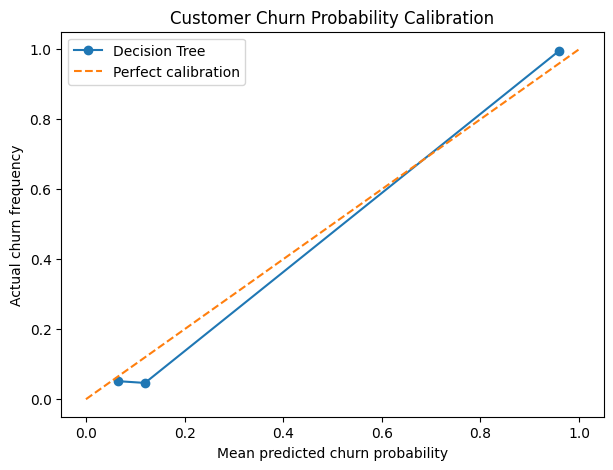

In [52]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

y_prob = calibrated_model.predict_proba(X_test_scaled)[:, 1]

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(mean_predicted, fraction_positive, marker="o", label="Decision Tree")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted churn probability")
plt.ylabel("Actual churn frequency")
plt.title("Customer Churn Probability Calibration")
plt.legend()
plt.show()

In [53]:
import pickle

# Save the calibrated model
with open("model.pkl", "wb") as f:
    pickle.dump(calibrated_model, f)

# Save the SAME scaler used to transform X_train
with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Final model and scaler saved successfully!")

Final model and scaler saved successfully!


In [54]:
from google.colab import files

files.download("model.pkl")
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
files.download("scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>